In [34]:
import time
import numpy as np
import matplotlib.pyplot as plt

In [35]:
DATA_PATH = "/mnist.npz"

with np.load(DATA_PATH) as data:
    X_train_img = data["x_train"]
    y_train = data["y_train"]
    X_test_img = data["x_test"]
    y_test = data["y_test"]

print("Обучающая выборка:", X_train_img.shape[0], "примеров")
print("Тестовая выборка: ", X_test_img.shape[0], "примеров")
print("Форма одного изображения:", X_train_img[0].shape)
print("train", y_train.shape, "test", y_test.shape)

Обучающая выборка: 60000 примеров
Тестовая выборка:  10000 примеров
Форма одного изображения: (28, 28)
train (60000,) test (10000,)


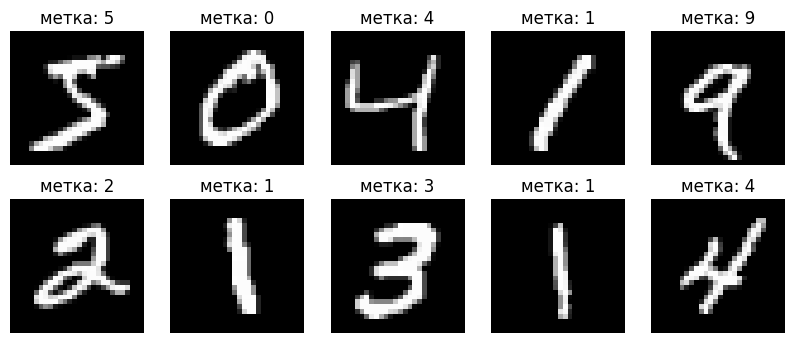

In [36]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_img[i], cmap="gray")
    plt.title(f"метка: {y_train[i]}")
    plt.axis("off")
plt.show()

In [37]:
X_train = X_train_img.reshape(-1, 784).astype(np.float32) / 255
X_test = X_test_img.reshape(-1, 784).astype(np.float32) / 255
Y_train = np.eye(10, dtype=np.float32)[y_train] # one-hot

In [38]:
def relu(z):
    return np.maximum(z, 0)


def relu_grad(z):
    return (z > 0).astype(z.dtype)


def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def he_init(rng, shape_in, shape_out):
    return (rng.standard_normal((shape_in, shape_out)) * np.sqrt(2 / shape_in)).astype(np.float32)

In [39]:
HIDDEN = 300 # скрытый слой

rng = np.random.default_rng(42)

W1 = he_init(rng, 784, HIDDEN)
b1 = np.zeros(HIDDEN, dtype=np.float32)
W2 = he_init(rng, HIDDEN, 10)
b2 = np.zeros(10, dtype=np.float32)

In [40]:
def forward(X, W1, b1, W2, b2):
    z1 = X @ W1 + b1
    h = relu(z1)
    z2 = h @ W2 + b2
    p = softmax(z2)
    return z1, h, p


def backward(X, Y, z1, h, p, W2):
    batch_size = len(X)
    out_error = (p - Y) / batch_size
    grad_W2 = h.T @ out_error
    grad_b2 = out_error.sum(axis=0)
    hidden_error = (out_error @ W2.T) * relu_grad(z1)
    grad_W1 = X.T @ hidden_error
    grad_b1 = hidden_error.sum(axis=0)
    return grad_W1, grad_b1, grad_W2, grad_b2


def predict(X, W1, b1, W2, b2):
    return forward(X, W1, b1, W2, b2)[2].argmax(axis=1)


def error_rate(X, y, W1, b1, W2, b2):
    return np.mean(predict(X, W1, b1, W2, b2) != y)

In [41]:
LEARNING_RATE = 0.1
BATCH_SIZE = 64
EPOCHS = 20

for epoch in range(1, EPOCHS + 1):
    t0 = time.perf_counter()
    perm = rng.permutation(len(X_train))

    for start in range(0, len(X_train), BATCH_SIZE):
        idx = perm[start:start + BATCH_SIZE]
        Xb, Yb = X_train[idx], Y_train[idx]

        z1, h, prob = forward(Xb, W1, b1, W2, b2)
        grad_W1, grad_b1, grad_W2, grad_b2 = backward(Xb, Yb, z1, h, prob, W2)

        W1 -= LEARNING_RATE * grad_W1
        b1 -= LEARNING_RATE * grad_b1
        W2 -= LEARNING_RATE * grad_W2
        b2 -= LEARNING_RATE * grad_b2

    train_error = error_rate(X_train, y_train, W1, b1, W2, b2)
    epoch_time = time.perf_counter() - t0
    print(
        f"Эпоха {epoch:2d}/{EPOCHS}  "
        f"Ошибка на train: {train_error * 100:.2f}%  "
        f"Время: {epoch_time:.2f} с"
    )

Эпоха  1/20  Ошибка на train: 5.97%  Время: 5.79 с
Эпоха  2/20  Ошибка на train: 4.05%  Время: 2.51 с
Эпоха  3/20  Ошибка на train: 3.29%  Время: 2.44 с
Эпоха  4/20  Ошибка на train: 2.59%  Время: 2.43 с
Эпоха  5/20  Ошибка на train: 2.10%  Время: 5.73 с
Эпоха  6/20  Ошибка на train: 1.85%  Время: 2.52 с
Эпоха  7/20  Ошибка на train: 1.63%  Время: 2.46 с
Эпоха  8/20  Ошибка на train: 1.30%  Время: 2.52 с
Эпоха  9/20  Ошибка на train: 1.12%  Время: 2.74 с
Эпоха 10/20  Ошибка на train: 0.97%  Время: 5.47 с
Эпоха 11/20  Ошибка на train: 0.85%  Время: 2.50 с
Эпоха 12/20  Ошибка на train: 0.78%  Время: 2.48 с
Эпоха 13/20  Ошибка на train: 0.69%  Время: 2.47 с
Эпоха 14/20  Ошибка на train: 0.53%  Время: 5.84 с
Эпоха 15/20  Ошибка на train: 0.43%  Время: 2.53 с
Эпоха 16/20  Ошибка на train: 0.41%  Время: 2.60 с
Эпоха 17/20  Ошибка на train: 0.35%  Время: 2.48 с
Эпоха 18/20  Ошибка на train: 0.29%  Время: 2.91 с
Эпоха 19/20  Ошибка на train: 0.25%  Время: 5.33 с
Эпоха 20/20  Ошибка на train: 0

In [42]:
test_error = error_rate(X_test, y_test, W1, b1, W2, b2)
print(f"Ошибка классификации на тестовой выборке: {test_error * 100:.2f}%")

Ошибка классификации на тестовой выборке: 1.86%


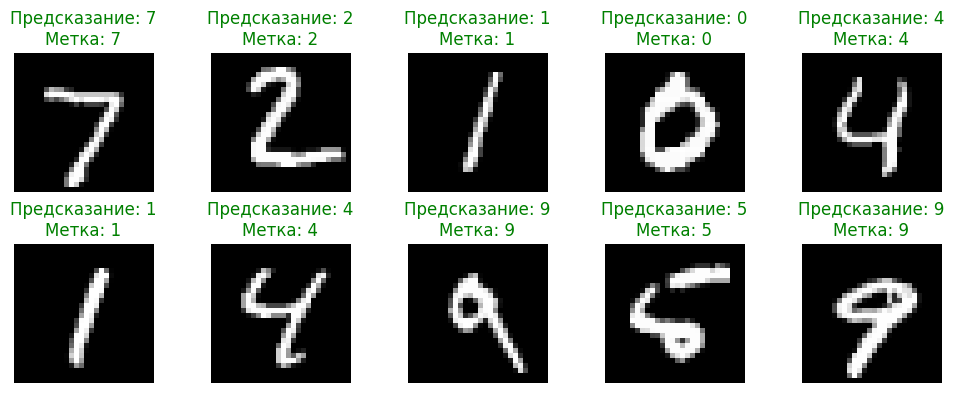

In [43]:
plt.figure(figsize=(10, 4))

predictions = predict(X_test[:10], W1, b1, W2, b2)

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test_img[i], cmap="gray")

    color = "green" if predictions[i] == y_test[i] else "red"
    plt.title(
        f"Предсказание: {predictions[i]}\nМетка: {y_test[i]}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()